# 2.19 · Convergence, mixing, R-hat and Monte Carlo error

**Before this:** [2.16](2-16_metropolis.ipynb) (Metropolis, ESS), [2.18](2-18_gradients_hmc_nuts.ipynb) (NUTS); [2.05](2-05_lln_clt.ipynb) for Monte Carlo error.
**You will be able to:** read warm-up, trace plots and R-hat; tell what R-hat can and cannot detect; use chain ranges
and per-chain potential energy as symptoms (not proofs) of ridges or separate modes; compute and report the Monte
Carlo standard error of the number you actually publish.
**Optional sections:** 7 (potential energy).

A sampler never announces "I am done". All we get is a long list of numbers, and we have to decide whether they
are draws from the posterior. Three questions hide behind the vague word "converged":
1. Has the chain **forgotten where it started**? (warm-up / burn-in)
2. Does it **move around the posterior quickly**? (mixing, autocorrelation, ESS)
3. Do **several independent chains agree**? (R-hat)

This notebook makes each one visible, and shows the cases where the usual diagnostics give the wrong answer.

**Words this notebook defines:** warm-up (burn-in), stationary distribution, convergence, mixing, trace plot,
R-hat (between-chain vs within-chain variance), split and rank-normalised R-hat, effective sample size (reminder;
2.05, 2.16), bulk and tail ESS, Monte Carlo standard error (MCSE), ridge vs multimodality, per-chain potential
energy.

**Problems in this notebook** (size and forward model; notebook 2.25 explains the degree of nonlinearity)

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| trade-off | 2 | 2 | $\mathbf d = \mathbf G\mathbf m$ | linear |
| round Gaussian (trace dictionary) | 2 | 2 | $\mathbf d = \mathbf G\mathbf m$ | linear |
| two modes | 2 | 2 | distances to two stations | nonlinear |
| flat ridge with a flat prior | 2 | 1 | $d = m_1 + m_2$ | linear (improper posterior) |
| main mode + minor mode (energy diagnostic) | 2 | none | target density only | no data |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import inspect
import numpy as np
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

CH = S.CHAINS                                     # chain 1..4 colours (identity only, not samplers)
pr = P.correlated()
gC = P.grid(pr, n=300)
mC, CC = pr.exact

## 1. Warm-up: forgetting the starting point

Four Metropolis chains on the trade-off posterior from notebook 2.02, started deliberately far away in four
different corners. The posterior is the chain's **stationary distribution**: once a chain is distributed like the
posterior, every further step keeps it so. The **warm-up** (or burn-in) is the transient before that happens.
Draws from the warm-up are not samples of the posterior and are thrown away.

iteration at which each chain first enters the 99 % region: [57, 24, 97, 98]
acceptance rate 0.30


saved figures/2-19_warmup.png


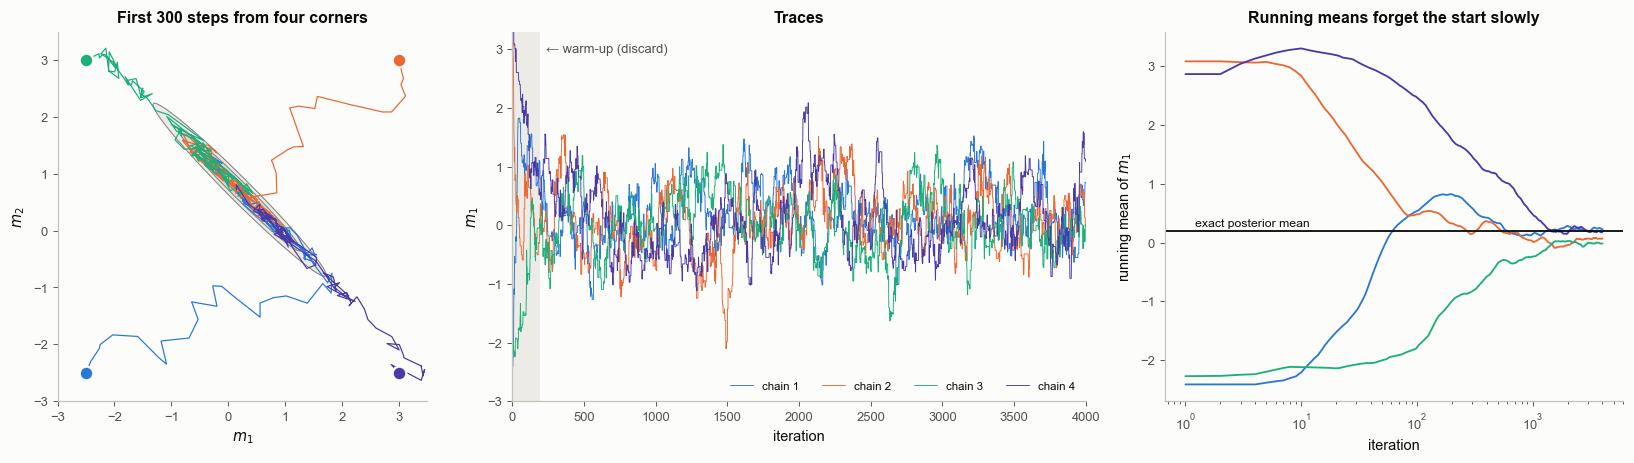

In [2]:
starts = np.array([[-2.5, -2.5], [3.0, 3.0], [-2.5, 3.0], [3.0, -2.5]])
warm = SM.rwm(pr, starts, 4000, step=0.25, rng=np.random.default_rng(1))
Sw = warm["samples"]
lev99 = gC.levels[0.99]
dens = lambda X: np.exp(np.asarray(pr._batch(jnp.asarray(X))))     # unnormalised posterior density
peak = dens(np.array([mC]))[0]                                     # the peak (mean = mode for this Gaussian)
first_in = []
for c in range(4):
    rel = dens(Sw[c]) / peak                                        # density relative to the peak
    first_in.append(int(np.argmax(rel >= lev99 / gC.P.max())))
print("iteration at which each chain first enters the 99 % region:", first_in)
print("acceptance rate %.2f" % warm["accept_rate"])
n_warm = int(max(first_in) * 2)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw=dict(width_ratios=[1, 1.5, 1.2]))
ax = axs[0]
BP.density(ax, gC)
for c in range(4):
    path = np.vstack([starts[c], Sw[c, :300]])
    ax.plot(path[:, 0], path[:, 1], "-", color=CH[c], lw=0.8)
    ax.plot(*starts[c], "o", color=CH[c], ms=9, mec=S.SURFACE, mew=1.5)
BP.frame(ax, pr, equal=True)
ax.set_title("First 300 steps from four corners")
ax = axs[1]
ax.axvspan(0, n_warm, color="#ecebe6", lw=0)
for c in range(4):
    ax.plot(Sw[c, :, 0], color=CH[c], lw=0.6, label=f"chain {c + 1}")
ax.text(n_warm + 40, 3.1, "← warm-up (discard)", ha="left", va="top", fontsize=8.5, color=S.INK2)
ax.set_xlim(0, Sw.shape[1]); ax.set_ylim(-3, 3.3)
ax.set_xlabel("iteration"); ax.set_ylabel("$m_1$")
ax.set_title("Traces")
ax.legend(loc="lower right", ncol=4, fontsize=7.5)
ax = axs[2]
it = np.arange(1, Sw.shape[1] + 1)
for c in range(4):
    ax.plot(it, np.cumsum(Sw[c, :, 0]) / it, color=CH[c], lw=1.2)
ax.axhline(mC[0], color=S.INK, lw=1.2)
ax.text(1.2, mC[0] + 0.08, "exact posterior mean", fontsize=8, color=S.INK)
ax.set_xscale("log")
ax.set_xlabel("iteration"); ax.set_ylabel("running mean of $m_1$")
ax.set_title("Running means forget the start slowly")
fig.tight_layout()
bk.savefig(fig, "2-19_warmup")
plt.show()

**How to read it.** Every chain first runs downhill onto the ridge (within about a hundred steps, printed above), then wanders
along it. The shaded part of the traces is the warm-up. The running means (right, log axis) still carry the memory of
the start long after the chains reached the ridge, which is exactly why warm-up draws are discarded.

**Converged** means: the chain's draws are now distributed like the posterior. You can never prove it from the
output. You can only fail to detect non-convergence, and the tools for detecting it are below. (In NUTS the warm-up
also tunes the step size and the mass matrix, notebook 2.18, which is another reason those draws are discarded.)

## 2. R-hat in one picture: do the chains agree?

Run several chains from dispersed starts. If they all sample the same distribution, each chain on its own shows
the full spread, and the chain means sit close together. If they have not converged, each chain covers only part
of the posterior and the means disagree. R-hat (Gelman & Rubin 1992) compares the two kinds of spread:

$$W = \text{mean of the within-chain variances},\qquad \frac{B}{n} = \text{variance of the chain means},$$
$$\widehat{\text{var}}^+ = \frac{n-1}{n}W + \frac{B}{n},\qquad \hat R = \sqrt{\widehat{\text{var}}^+ / W}.$$

When the chains agree, $B/n$ is tiny compared with $W$ and $\hat R \approx 1$. When they disagree, the between-chain
spread inflates $\widehat{\text{var}}^+$ and $\hat R > 1$. Two refinements are standard today (Vehtari et al. 2021):
**split** R-hat cuts each chain in half (so a chain whose first half differs from its second half also counts as
disagreement), and **rank-normalised** R-hat replaces values by the normal scores of their ranks (robust to heavy
tails), taking the worse of a "bulk" and a "tail" version. The recommended threshold is $\hat R < 1.01$.

In [3]:
print(inspect.getsource(D.rhat_classic))
print(inspect.getsource(D.rhat))

def rhat_classic(x):
    """Original Gelman-Rubin potential scale reduction factor on (C, n) draws of one scalar."""
    x = _as_chains(x)
    C, n = x.shape
    means = x.mean(1)
    B = n * means.var(ddof=1)                                 # between-chain variance (times n)
    W = x.var(1, ddof=1).mean()                               # mean within-chain variance
    var_plus = (n - 1) / n * W + B / n
    return float(np.sqrt(var_plus / W))

def rhat(x):
    """Rank-normalised split R-hat (Vehtari et al. 2021): max of the bulk and tail versions."""
    xs = split(x)
    bulk = rhat_classic(_rank_normalise(xs))
    folded = np.abs(xs - np.median(xs))
    tail = rhat_classic(_rank_normalise(folded))
    return max(bulk, tail)



(a) chains agree: W = 0.2687, B/n = 0.0010, classic R-hat = 1.002, rank-normalised split R-hat = 1.003
(b) chains disagree: W = 0.1075, B/n = 0.3281, classic R-hat = 2.013, rank-normalised split R-hat = 2.520


saved figures/2-19_rhat_picture.png


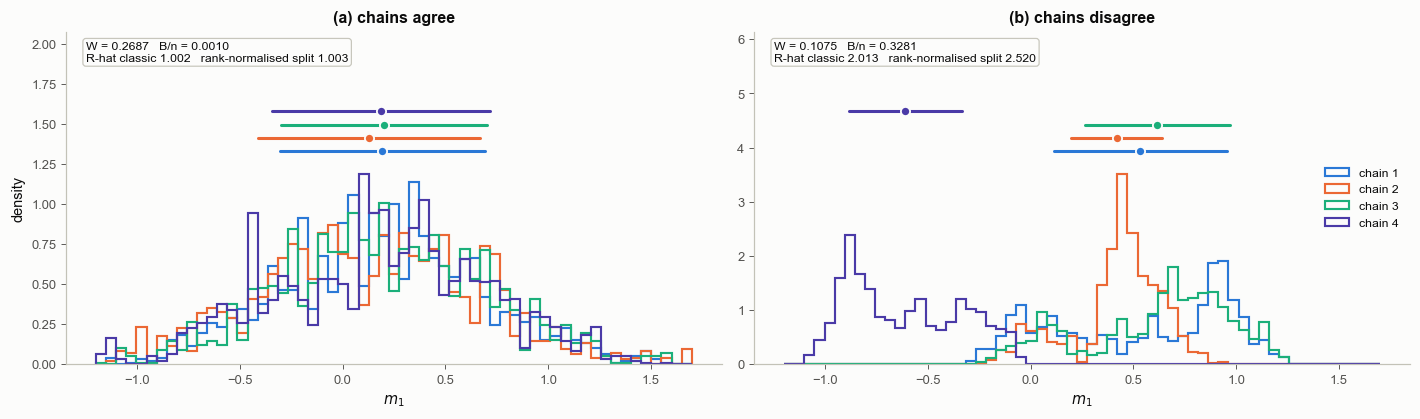

In [4]:
# (a) chains that agree: proposals shaped like the posterior, started from posterior draws
rng = np.random.default_rng(4)
st_post = mC + rng.standard_normal((4, 2)) @ np.linalg.cholesky(CC).T
agree = SM.rwm(pr, st_post, 2000, step=1.0, cov=CC * 2.38 ** 2 / 2, rng=np.random.default_rng(5))
# (b) chains that disagree: tiny steps, started at four points spread along the ridge
v_long = np.linalg.eigh(CC)[1][:, 1]
sd_long = np.sqrt(np.linalg.eigvalsh(CC)[1])
st_spread = mC + np.outer([-1.6, -0.55, 0.55, 1.6], v_long) * sd_long
disagree = SM.rwm(pr, st_spread, 2000, step=0.02, rng=np.random.default_rng(6))


def parts(x):
    n = x.shape[1]
    W = x.var(1, ddof=1).mean()
    Bn = x.mean(1).var(ddof=1)
    return W, Bn, np.sqrt(((n - 1) / n * W + Bn) / W)


fig, axs = plt.subplots(1, 2, figsize=(13, 3.9), sharex=True)
bins = np.linspace(-1.2, 1.7, 60)
for ax, r, t in zip(axs, [agree, disagree], ["(a) chains agree", "(b) chains disagree"]):
    x = r["samples"][:, :, 0]
    W, Bn, rc = parts(x)
    top = 0
    for c in range(4):
        h, _, _ = ax.hist(x[c], bins=bins, density=True, histtype="step", color=CH[c], lw=1.4, label=f"chain {c + 1}")
        top = max(top, h.max())
    y0 = top * 1.12
    for c in range(4):
        mu, sd = x[c].mean(), x[c].std()
        ax.plot([mu - sd, mu + sd], [y0 + c * top * 0.07] * 2, "-", color=CH[c], lw=2.0)
        ax.plot(mu, y0 + c * top * 0.07, "o", color=CH[c], ms=6, mec=S.SURFACE, mew=1.2)
    ax.set_ylim(0, top * 1.75)
    ax.set_title(t)
    ax.set_xlabel("$m_1$")
    S.badge(ax, f"W = {W:.4f}   B/n = {Bn:.4f}\nR-hat classic {rc:.3f}   rank-normalised split {D.rhat(x):.3f}",
            loc="upper left", fs=8)
    print(f"{t}: W = {W:.4f}, B/n = {Bn:.4f}, classic R-hat = {rc:.3f}, rank-normalised split R-hat = {D.rhat(x):.3f}")
axs[0].set_ylabel("density")
axs[1].legend(loc="center right", fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-19_rhat_picture")
plt.show()

Bars above the histograms: each chain's mean ± one within-chain standard deviation. In (a) the bars line up and
every chain's histogram looks like the others; in (b) each chain explores only its own stretch of the ridge, the
means spread out, and R-hat is far above 1.01.

## 3. R-hat against run length

Same four corner starts, three samplers of different quality. For each run length $n$ we discard the first half as
warm-up and compute R-hat of $m_1$ on the second half.

proposal shaped like the posterior  : R-hat at n = 20000 is 1.001; first n with R-hat < 1.01: 1257


isotropic, step 0.25                : R-hat at n = 20000 is 1.015; first n with R-hat < 1.01: never


isotropic, step 0.02 (too small)    : R-hat at n = 20000 is 1.433; first n with R-hat < 1.01: never
saved figures/2-19_rhat_vs_length.png


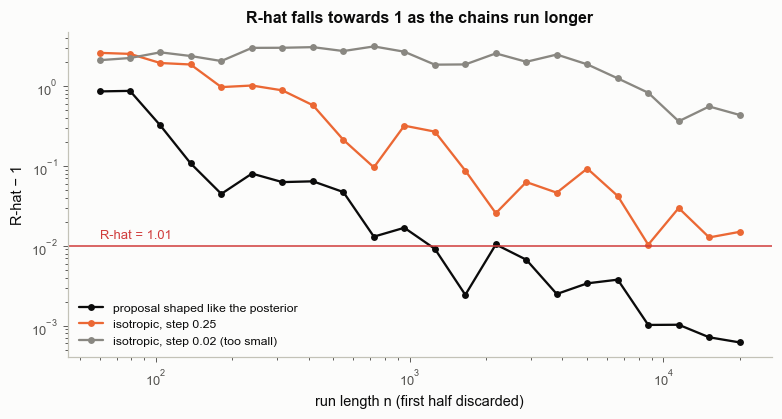

In [5]:
configs = {"proposal shaped like the posterior": dict(step=1.0, cov=CC * 2.38 ** 2 / 2),
           "isotropic, step 0.25": dict(step=0.25),
           "isotropic, step 0.02 (too small)": dict(step=0.02)}
ns = np.unique(np.geomspace(60, 20000, 22).astype(int))
curves = {}
for k, (name, kw) in enumerate(configs.items()):
    r = SM.rwm(pr, starts, 20000, rng=np.random.default_rng(40 + k), **kw)
    curves[name] = np.array([D.rhat(r["samples"][:, n // 2:n, 0]) for n in ns])
    below = ns[curves[name] < 1.01]
    print(f"{name:36s}: R-hat at n = 20000 is {curves[name][-1]:.3f}; first n with R-hat < 1.01: "
          f"{below[0] if below.size else 'never'}")
fig, ax = plt.subplots(figsize=(7.2, 3.9))
for (name, cv), col in zip(curves.items(), [S.INK, S.COLORS["rwm"], S.MUTED]):
    ax.plot(ns, cv - 1, "-o", ms=3.5, color=col, label=name)
ax.axhline(0.01, color=S.BAD, lw=1.0)
ax.text(ns[0], 0.0115, "R-hat = 1.01", color=S.BAD, fontsize=8.5, va="bottom")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("run length n (first half discarded)")
ax.set_ylabel("R-hat − 1")
ax.set_title("R-hat falls towards 1 as the chains run longer")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-19_rhat_vs_length")
plt.show()

A good sampler crosses the 1.01 line early; a poor one gets there much later or not within the run (printed above).
R-hat estimates are themselves noisy, so a single dip below the line is weaker evidence than a curve that stays
below it as the run grows.

## 4. A visual dictionary of trace plots

Five classic situations, four chains each (colours = chain identity). Left: where the chains went. Right: the trace
of one coordinate. The badge gives R-hat and ESS for that coordinate.

good mixing                              acceptance 0.35  R-hat 1.002  ESS 1010
step too small                           acceptance 0.97  R-hat 1.300  ESS 14
step too large (sticky)                  acceptance 0.01  R-hat 1.271  ESS 52
stuck in separate modes                  acceptance 0.36  R-hat 1.745  ESS 2
drifting on a flat ridge (flat prior)    acceptance 0.40  R-hat 2.437  ESS 3


saved figures/2-19_trace_dictionary.png


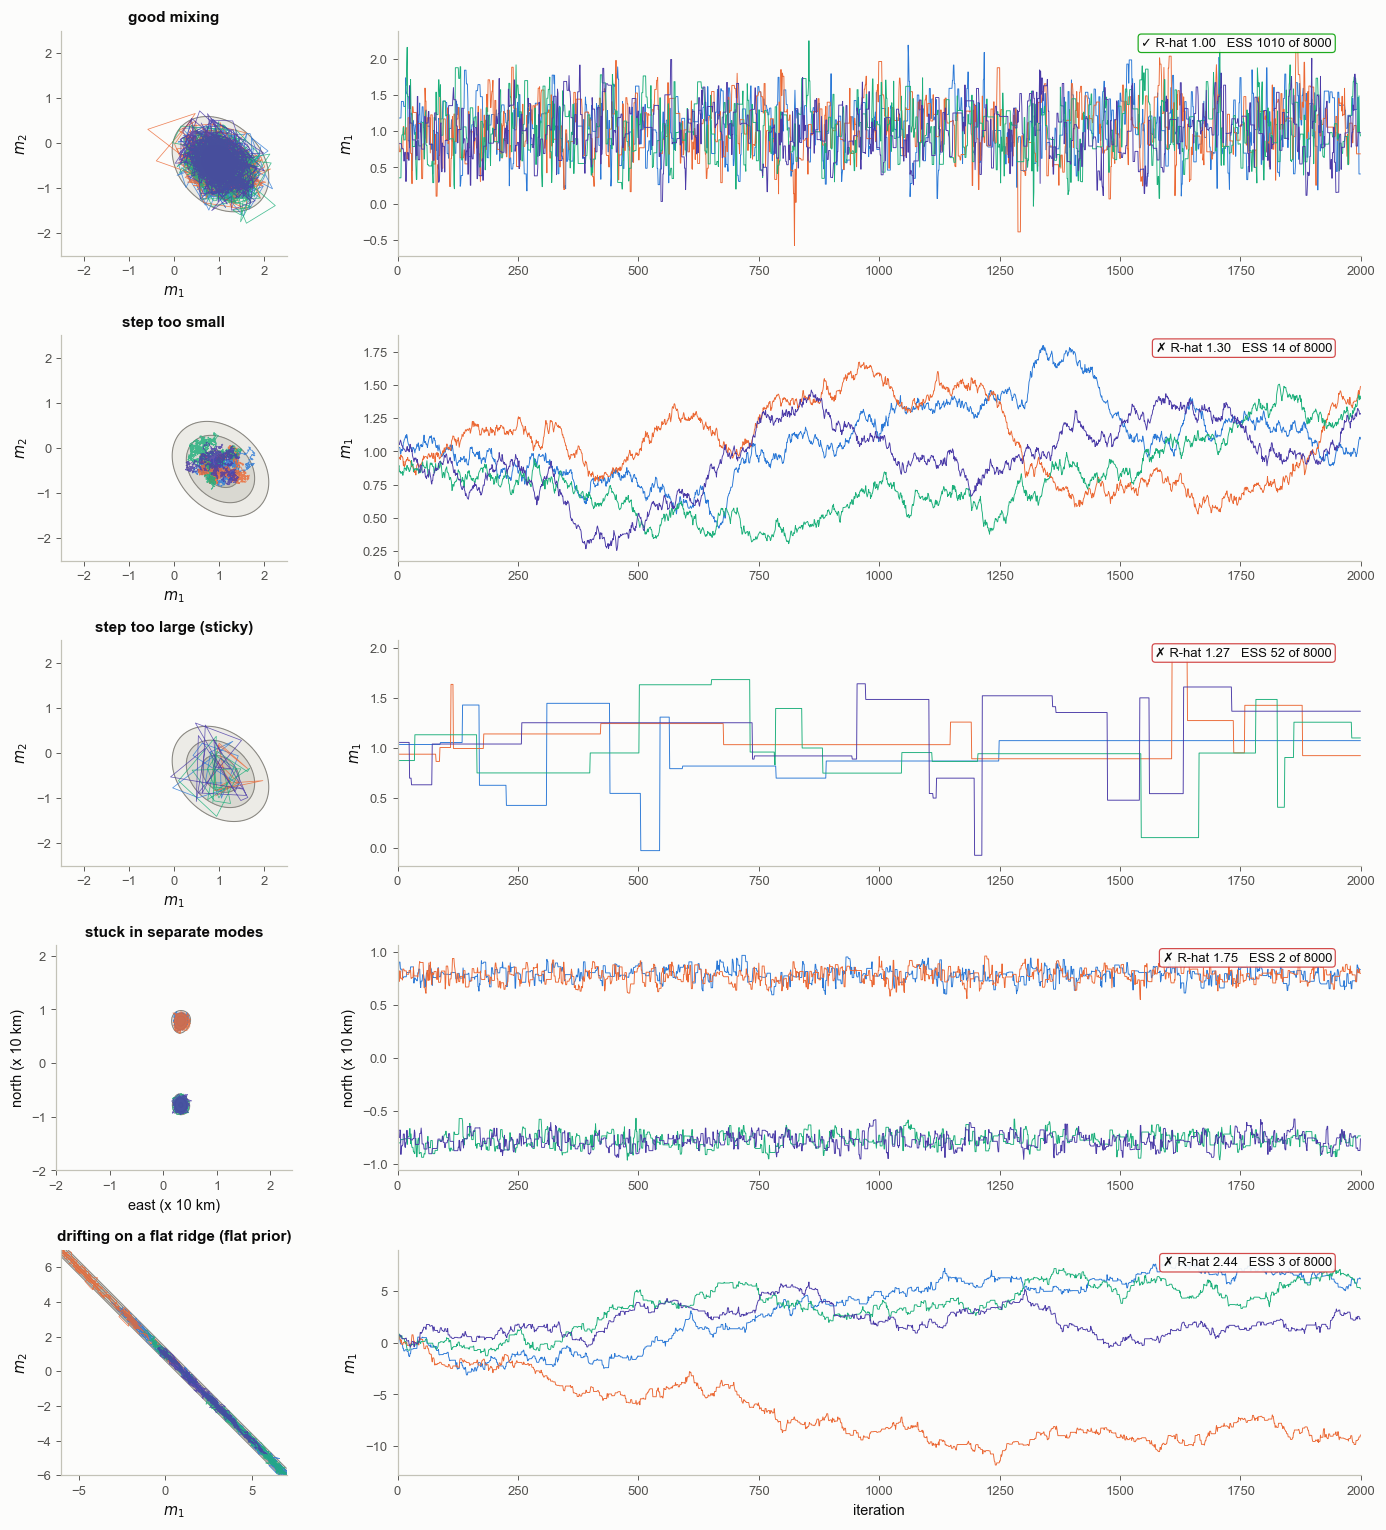

In [6]:
gp = P.gaussian()
gG = P.grid(gp, n=300)
mG, CG = gp.exact
bim = P.location(kind="bimodal")
gBm = P.grid(bim, n=400)
flat = P.flat_ridge("flat")
gF = P.grid(flat, n=300)
rng = np.random.default_rng(7)
st_g = mG + rng.standard_normal((4, 2)) @ np.linalg.cholesky(CG).T
st_bim = np.array([[0.3, 0.8], [0.35, 0.75], [0.3, -0.8], [0.35, -0.75]])
st_flat = np.array([[0.5, 0.5]] * 4) + 0.05 * rng.standard_normal((4, 2))
cases = [
    ("good mixing", gp, gG, SM.rwm(gp, st_g, 2000, step=0.6, rng=np.random.default_rng(71)), 0),
    ("step too small", gp, gG, SM.rwm(gp, st_g, 2000, step=0.02, rng=np.random.default_rng(72)), 0),
    ("step too large (sticky)", gp, gG, SM.rwm(gp, st_g, 2000, step=6.0, rng=np.random.default_rng(73)), 0),
    ("stuck in separate modes", bim, gBm, SM.rwm(bim, st_bim, 2000, step=0.1, rng=np.random.default_rng(74)), 1),
    ("drifting on a flat ridge (flat prior)", flat, gF, SM.rwm(flat, st_flat, 2000, step=0.3, rng=np.random.default_rng(75)), 0),
]
fig, axs = plt.subplots(5, 2, figsize=(13, 14), gridspec_kw=dict(width_ratios=[1, 2.6]))
for row, (name, prob, g, r, coord) in enumerate(cases):
    Sx = r["samples"]
    ax = axs[row, 0]
    BP.density(ax, g)
    for c in range(4):
        ax.plot(Sx[c, :, 0], Sx[c, :, 1], "-", color=CH[c], lw=0.5, alpha=0.8)
    BP.frame(ax, prob, equal=True)
    ax.set_title(name, fontsize=10)
    ax = axs[row, 1]
    for c in range(4):
        ax.plot(Sx[c, :, coord], color=CH[c], lw=0.6)
    ax.set_xlim(0, Sx.shape[1])
    ax.set_ylabel(prob.labels[coord])
    rh, es = D.rhat(Sx[:, :, coord]), D.ess(Sx[:, :, coord])
    S.badge(ax, f"R-hat {rh:.2f}   ESS {es:.0f} of {Sx.shape[0] * Sx.shape[1]}", ok=bool(rh < 1.01), loc="upper right")
    print(f"{name:40s} acceptance {r['accept_rate']:.2f}  R-hat {rh:.3f}  ESS {es:.0f}")
axs[-1, 1].set_xlabel("iteration")
fig.tight_layout()
bk.savefig(fig, "2-19_trace_dictionary")
plt.show()

**The five pictures to keep.**
* **Good mixing:** a "fuzzy caterpillar"; the four chains are indistinguishable.
* **Step too small:** each chain is a slow snake that has not yet left its own neighbourhood; R-hat is high
  although nothing is "stuck".
* **Step too large:** long flat stretches (rejections); few independent draws.
* **Separate modes:** two bands that never meet. Each chain is perfectly happy; together they disagree completely.
* **Flat ridge with a flat prior:** the chains drift apart without limit. Below: what R-hat does as this run gets
  longer.

n =    500: R-hat 2.25, range of m1 visited by all chains   10.3
n =   1442: R-hat 2.53, range of m1 visited by all chains   17.1
n =   4162: R-hat 2.25, range of m1 visited by all chains   27.8
n =  12011: R-hat 2.99, range of m1 visited by all chains   45.3
n =  34657: R-hat 2.63, range of m1 visited by all chains   68.3
n = 100000: R-hat 2.50, range of m1 visited by all chains  121.7
saved figures/2-19_flat_ridge_never_converges.png


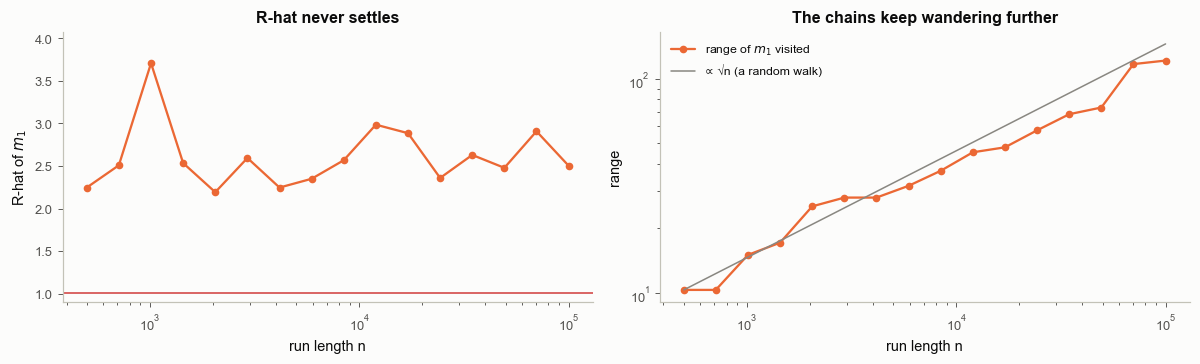

In [7]:
long_flat = SM.rwm(flat, st_flat, 100000, step=0.3, rng=np.random.default_rng(76))
nf = np.unique(np.geomspace(500, 100000, 16).astype(int))
rh_f = np.array([D.rhat(long_flat["samples"][:, n // 2:n, 0]) for n in nf])
span_f = np.array([np.ptp(long_flat["samples"][:, :n, 0]) for n in nf])
for n, a, b in zip(nf[::3], rh_f[::3], span_f[::3]):
    print(f"n = {n:6d}: R-hat {a:.2f}, range of m1 visited by all chains {b:6.1f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(nf, rh_f, "-o", color=S.COLORS["rwm"], ms=4)
axs[0].axhline(1.01, color=S.BAD, lw=1.0)
axs[0].set_xscale("log"); axs[0].set_ylim(0.9, max(4, rh_f.max() * 1.1))
axs[0].set_xlabel("run length n"); axs[0].set_ylabel("R-hat of $m_1$")
axs[0].set_title("R-hat never settles")
axs[1].loglog(nf, span_f, "-o", color=S.COLORS["rwm"], ms=4, label="range of $m_1$ visited")
axs[1].loglog(nf, span_f[0] * np.sqrt(nf / nf[0]), "-", color=S.MUTED, lw=1.0, label="∝ √n (a random walk)")
axs[1].set_xlabel("run length n"); axs[1].set_ylabel("range")
axs[1].set_title("The chains keep wandering further")
axs[1].legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-19_flat_ridge_never_converges")
plt.show()

With a flat prior along a direction the data cannot see, the posterior is improper (notebook 2.02): there is no
distribution to converge to. Running longer does not help. R-hat stays far above 1, and the range the chains visit
keeps growing roughly like a random walk. If you see this, the fix is in the model (a proper prior, or a
reparameterisation that removes the unidentified combination), never in the sampler settings.

## 5. Ridge or multiple modes? Per-chain ranges as a symptom

Both a slowly explored ridge and separate modes give a bad R-hat, and they need different remedies. A quick picture
that often hints at which one you face is the range (min to max) each chain visited. It is a symptom, not a test:
the bottom row shows both ways it can mislead.

slow ridge, 1,500 draws per chain: ranges overlap: R-hat 1.694; ranges [-0.56, 1.29], [0.01, 1.77], [-0.80, 0.72], [-0.60, 0.91]
two modes, north coordinate: ranges disjoint: R-hat 1.742; ranges [0.60, 0.94], [0.55, 0.96], [-0.96, -0.58], [-0.96, -0.58]
same connected ridge, first 100 draws: some ranges disjoint: R-hat 3.077; ranges [0.78, 1.09], [0.37, 0.84], [-0.28, 0.26], [-0.80, -0.43]
same two modes, east coordinate: ranges overlap: R-hat 1.014; ranges [0.20, 0.48], [0.18, 0.48], [0.17, 0.48], [0.16, 0.53]
saved figures/2-19_ridge_vs_modes.png


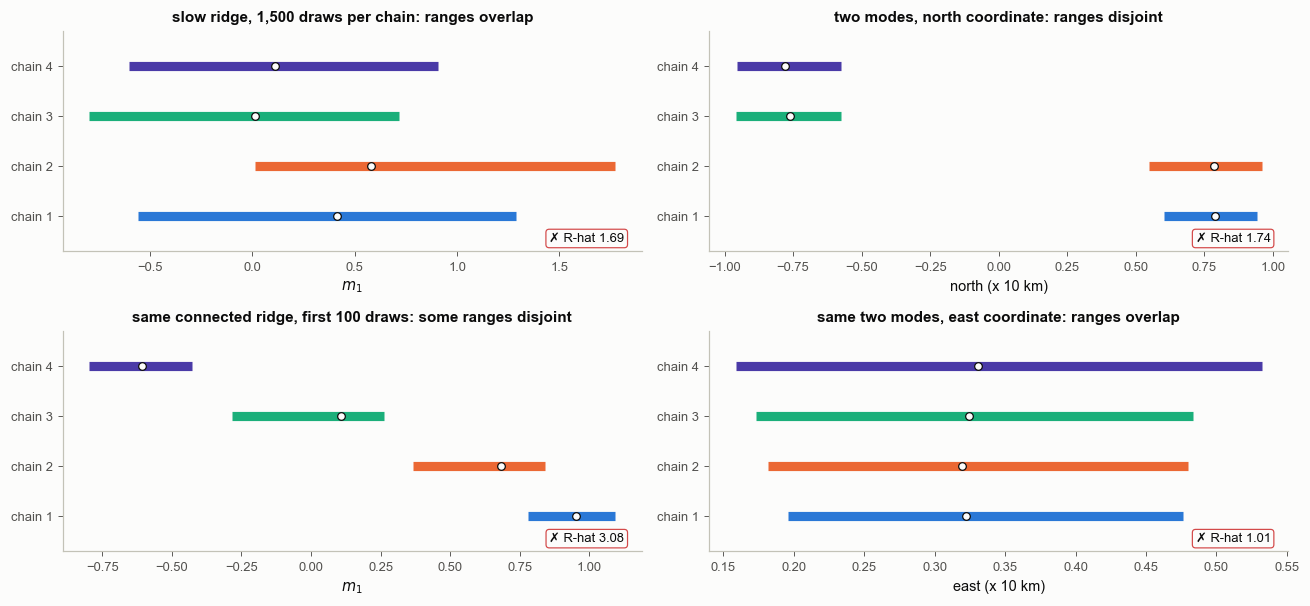

In [8]:
ridge = SM.rwm(pr, st_spread, 3000, step=0.05, rng=np.random.default_rng(8))
xr = ridge["samples"][:, 1500:, 0]
xr_short = ridge["samples"][:, :100, 0]
xm = cases[3][3]["samples"][:, 1000:, 1]
xm_east = cases[3][3]["samples"][:, 1000:, 0]
fig, axs = plt.subplots(2, 2, figsize=(12, 5.6))
for ax, x, t, lab in zip(axs.ravel(), [xr, xm, xr_short, xm_east],
                         ["slow ridge, 1,500 draws per chain: ranges overlap", "two modes, north coordinate: ranges disjoint",
                          "same connected ridge, first 100 draws: some ranges disjoint",
                          "same two modes, east coordinate: ranges overlap"],
                         ["$m_1$", "north (x 10 km)", "$m_1$", "east (x 10 km)"]):
    for c in range(4):
        ax.plot([x[c].min(), x[c].max()], [c, c], "-", color=CH[c], lw=6, solid_capstyle="butt")
        ax.plot(np.median(x[c]), c, "o", color=S.SURFACE, ms=5, mec=S.INK, mew=0.8)
    ax.set_yticks(range(4)); ax.set_yticklabels([f"chain {c + 1}" for c in range(4)])
    ax.set_ylim(-0.7, 3.7)
    ax.set_xlabel(lab)
    rh = D.rhat(x)
    ax.set_title(t, fontsize=10)
    S.badge(ax, f"R-hat {rh:.2f}", ok=bool(rh < 1.01), loc="lower right")
    print(f"{t}: R-hat {rh:.3f}; ranges " + ", ".join(f"[{x[c].min():.2f}, {x[c].max():.2f}]" for c in range(4)))
fig.tight_layout()
bk.savefig(fig, "2-19_ridge_vs_modes")
plt.show()

* **Top row, the typical pictures.** Ranges that overlap (left) are what one connected region explored too slowly
  usually looks like; ranges that are disjoint (right) are what separate islands of probability usually look like.
* **Bottom row, why it is only a symptom.** Left: the *same* connected ridge, after only 100 draws per chain,
  already has chains whose ranges do not overlap (printed). Right: the *same* two separate modes, seen in the east
  coordinate, overlap completely and R-hat for east is close to 1 (printed), because the modes differ only in the
  north coordinate.

So use the ranges together with other evidence: several coordinates and 2-D scatter plots, per-chain potential
energy (section 7), a longer run, and the physics (is there a symmetry that could create a second mode? section 6).
The remedies differ. A slowly explored connected region calls for a reparameterisation, a proposal or mass matrix
shaped like the posterior (2.16, 2.18), or a longer run. Separate islands call for a method designed to move
between modes, such as tempering and SMC (2.20), or for starts from several optimiser solutions. The two are not
exclusive: tempering can be combined with geometry-aware moves, and one posterior can have both problems.

## 6. R-hat = 1 does not mean "correct"

R-hat checks that chains agree with each other, not that they agree with the posterior. Start all four chains in
the northern mode of the two-station problem:

R-hat east 1.002, north 1.003;  ESS east 2741, north 2072 (of 20000 draws)
probability of the northern mode: chains 1.000, exact (grid) 0.686
saved figures/2-19_rhat_one_but_wrong.png


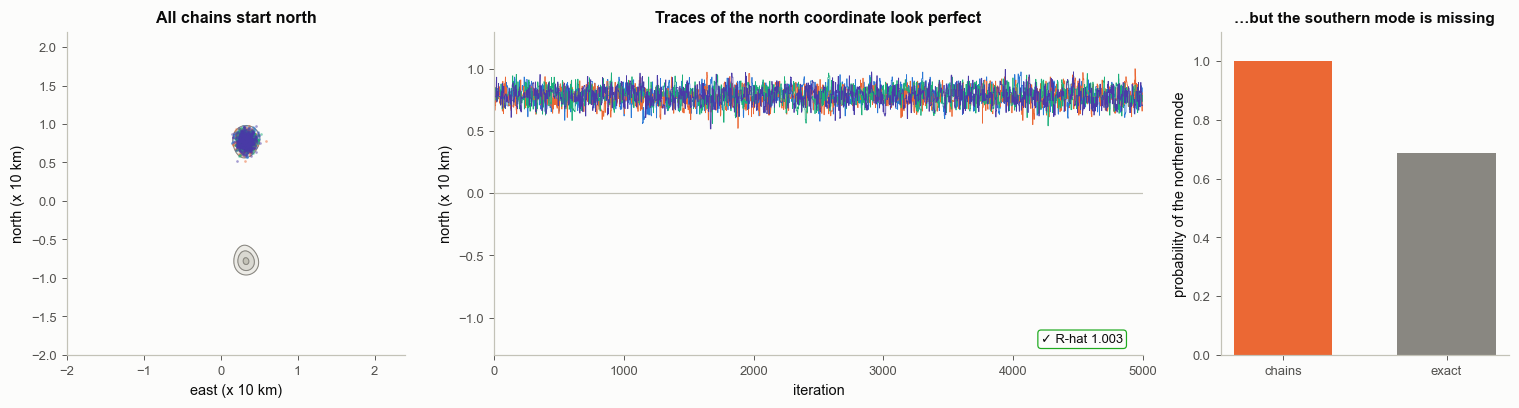

In [9]:
st_north = np.array([0.3, 0.8]) + 0.05 * np.random.default_rng(9).standard_normal((4, 2))
north = SM.rwm(bim, st_north, 5000, step=0.1, rng=np.random.default_rng(10))
Sn = north["samples"]
p_north_true = gBm.mass(lambda X, Y: Y > 0)
p_north_chain = np.mean(Sn[:, :, 1] > 0)
print("R-hat east %.3f, north %.3f;  ESS east %.0f, north %.0f (of %d draws)"
      % (D.rhat(Sn[:, :, 0]), D.rhat(Sn[:, :, 1]), D.ess(Sn[:, :, 0]), D.ess(Sn[:, :, 1]), Sn.shape[0] * Sn.shape[1]))
print("probability of the northern mode: chains %.3f, exact (grid) %.3f" % (p_north_chain, p_north_true))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1, 1.8, 0.8]))
ax = axs[0]
BP.density(ax, gBm)
for c in range(4):
    BP.samples(ax, Sn[c], CH[c], n_max=800, s=3, alpha=0.5)
BP.frame(ax, bim, equal=True)
ax.set_title("All chains start north")
ax = axs[1]
for c in range(4):
    ax.plot(Sn[c, :, 1], color=CH[c], lw=0.5)
ax.set_xlim(0, Sn.shape[1]); ax.set_ylim(-1.3, 1.3)
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("iteration"); ax.set_ylabel(bim.labels[1])
ax.set_title("Traces of the north coordinate look perfect")
S.badge(ax, f"R-hat {D.rhat(Sn[:, :, 1]):.3f}", ok=bool(D.rhat(Sn[:, :, 1]) < 1.01), loc="lower right")
ax = axs[2]
ax.bar([0, 1], [p_north_chain, p_north_true], color=[S.COLORS["rwm"], S.MUTED], width=0.6)
ax.set_xticks([0, 1]); ax.set_xticklabels(["chains", "exact"])
ax.set_ylim(0, 1.1); ax.set_ylabel("probability of the northern mode")
ax.set_title("…but the southern mode is missing", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-19_rhat_one_but_wrong")
plt.show()

Every diagnostic is green and the answer is wrong: the southern mode, which holds the probability printed above,
is simply never visited. Defences: start chains from widely dispersed points (from the prior, or several optimiser
solutions), look at the physics for symmetries (a polarity, a mirror location, a nodal-plane ambiguity), and use a
method that can cross between modes (tempering, notebook 2.20).

## 7. Per-chain potential energy: the first thing to print

The **potential energy** of a draw is $U = -\log p(\mathbf m \mid \mathbf d)$ (the height in the landscape that HMC
slides on). Chains sampling the same distribution have the same distribution of $U$. A chain trapped somewhere
less probable sits at visibly higher $U$. Example: a posterior with a dominant mode and a small secondary mode, far
enough apart that no chain crosses during the run; three chains start in the main mode and one in the small one.
(In a first version the minor mode sat closer, and the trapped chain escaped after a while: the tail of the main
mode filled the valley between them.)

chain 1: median potential energy 0.70
chain 2: median potential energy 0.68
chain 3: median potential energy 0.70
chain 4: median potential energy 4.63
difference expected from the mode weights alone: log(0.98/0.02) = 3.89
R-hat of m1 = 1.53; fraction of draws in the minor mode: chains 0.250, exact 0.020
saved figures/2-19_potential_energy.png


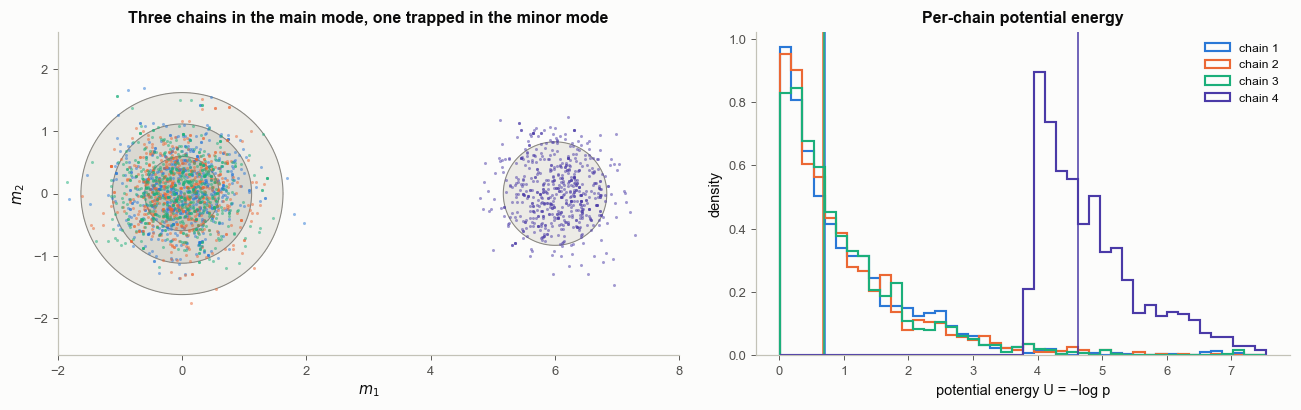

In [10]:
w_main, w_minor, sd_m = 0.98, 0.02, 0.5
mu_main, mu_minor = jnp.array([0.0, 0.0]), jnp.array([6.0, 0.0])


def lp_mix(x):
    a = jnp.log(w_main) - 0.5 * jnp.sum((x - mu_main) ** 2) / sd_m ** 2
    b = jnp.log(w_minor) - 0.5 * jnp.sum((x - mu_minor) ** 2) / sd_m ** 2
    return jnp.logaddexp(a, b)


mix = P.Target(lp_mix, 2, name="dominant + minor mode", extent=(-2, 8, -2.6, 2.6), labels=("$m_1$", "$m_2$"))
gM = P.grid(mix, n=300)
st_mix = np.array([[0.0, 0.0], [0.1, -0.1], [-0.1, 0.1], [6.0, 0.0]])
rm = SM.rwm(mix, st_mix, 4000, step=0.6, rng=np.random.default_rng(12))
U = -rm["logp"][:, 500:]
med = np.median(U, axis=1)
for c in range(4):
    print(f"chain {c + 1}: median potential energy {med[c]:.2f}")
print("difference expected from the mode weights alone: log(%.2f/%.2f) = %.2f" % (w_main, w_minor, np.log(w_main / w_minor)))
print("R-hat of m1 = %.2f; fraction of draws in the minor mode: chains %.3f, exact %.3f"
      % (D.rhat(rm["samples"][:, 500:, 0]), np.mean(rm["samples"][:, 500:, 0] > 3.0), gM.mass(lambda X, Y: X > 3.0)))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax = axs[0]
BP.density(ax, gM)
for c in range(4):
    BP.samples(ax, rm["samples"][c, 500:], CH[c], n_max=600, s=4, alpha=0.5)
BP.frame(ax, mix, equal=True)
ax.set_title("Three chains in the main mode, one trapped in the minor mode")
ax = axs[1]
bins = np.linspace(U.min(), np.percentile(U, 99.5), 45)
for c in range(4):
    ax.hist(U[c], bins=bins, histtype="step", color=CH[c], lw=1.4, density=True, label=f"chain {c + 1}")
    ax.axvline(med[c], color=CH[c], lw=1.0)
ax.set_xlabel("potential energy U = −log p")
ax.set_ylabel("density")
ax.set_title("Per-chain potential energy")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-19_potential_energy")
plt.show()

The trapped chain's energy distribution is shifted to the right by about the log of the weight ratio (printed
above): it lives in a less probable place. R-hat is large here too, but the energy picture says *why*: one chain
differs, and it differs by being stuck somewhere worse, not by exploring the same region slowly.

In practice the per-chain median potential energy is a cheap first diagnostic on any multi-chain run: a chain
stuck somewhere less probable stands out at once. A related habit: before comparing two sampler configurations, run
the identical configuration twice and see how much the diagnostics move by chance (the noise floor).

## 8. How precise is the number you report? Monte Carlo standard error

**In plain words.** A posterior mean or a 95 % bound computed from draws is itself an estimate: run the sampler
again with another seed and you get a slightly different number. That wobble is the **Monte Carlo error** (2.05),
caused by using finitely many, correlated draws. It is not the posterior uncertainty: the posterior standard
deviation says how uncertain the parameter is; the **Monte Carlo standard error (MCSE)** says how precisely the
computation pinned down the number you quote. The MCSE shrinks as the run grows; the posterior sd does not.

**Precisely** (Vehtari et al. 2021). For the posterior mean, $\text{MCSE} \approx \text{sd}/\sqrt{\text{ESS}}$,
with the ESS of the draws themselves. For a quantile (a 5 % or 95 % bound) the relevant ESS is that of the
indicator "draw below the quantile", and the MCSE comes from the uncertainty of that proportion mapped back through
the empirical quantiles. Two summaries of efficiency are standard: **bulk ESS**, the ESS of the rank-normalised
draws (how well the centre of the distribution is sampled), and **tail ESS**, the smaller of the ESS of the
indicators below the 5 % and above the 95 % quantiles (how well the tails are sampled). Even from the same draws a
tail quantile is estimated less precisely than the mean, because few draws fall near it; and some samplers also
explore the tails more slowly than the centre, which a small tail ESS reveals.

**The test.** The trade-off posterior is Gaussian, so the exact mean and 5 % quantile of $m_1$ are known. Two
samplers (proposals shaped like the posterior; isotropic steps of 0.25), 40 repeats each with different seeds,
4 chains × 2,000 steps, first 500 discarded. For every repeat we compute the estimate and its MCSE, then check the
MCSE against how much the estimates actually scatter around the exact values.

proposals shaped like the posterior:
   posterior sd of m1 (estimated) 0.494; bulk ESS 820, tail ESS 971 (medians over 40 repeats, of 6000 draws)
   mean: median MCSE 0.0176; actual scatter of the 40 estimates around the exact mean 0.0155; exact value inside estimate ± 2 MCSE in 0.95 of the repeats
   5 % quantile: median MCSE 0.0308; actual scatter 0.0378; exact inside ± 2 MCSE in 0.88 of the repeats


isotropic, step 0.25:
   posterior sd of m1 (estimated) 0.494; bulk ESS 51, tail ESS 114 (medians over 40 repeats, of 6000 draws)
   mean: median MCSE 0.0656; actual scatter of the 40 estimates around the exact mean 0.0477; exact value inside estimate ± 2 MCSE in 1.00 of the repeats
   5 % quantile: median MCSE 0.0841; actual scatter 0.0802; exact inside ± 2 MCSE in 0.95 of the repeats
saved figures/2-19_mcse.png


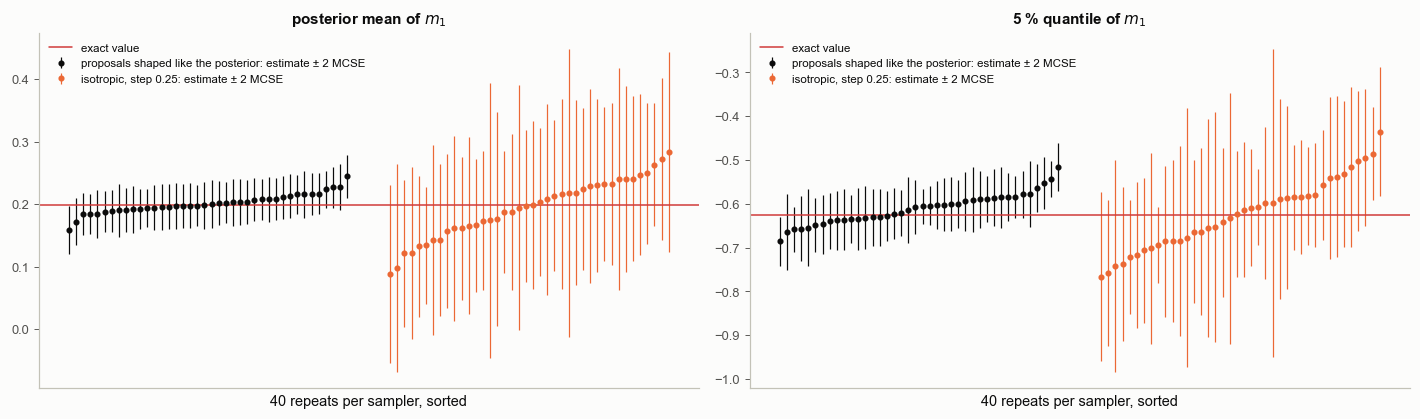

In [11]:
from scipy.stats import beta as BETA, norm as NORM


def ess_safe(x):
    """D.ess, except that a chain whose values never change (possible for an indicator in a sticky chain) contributes
    zero autocovariance instead of 0/0."""
    x = np.asarray(x, float)
    C, n = x.shape
    acov = np.array([D.autocorr(c) * c.var() if c.var() > 0 else np.zeros(n) for c in x])
    W = x.var(1, ddof=1).mean()
    var_plus = W * (n - 1) / n + x.mean(1).var(ddof=1)
    if var_plus <= 0:
        return float("nan")
    rho = 1.0 - (W - acov.mean(0)) / var_plus
    rho[0] = 1.0
    pair, prev = [], np.inf
    for k in range(0, n - 1, 2):
        ps = rho[k] + rho[k + 1]
        if ps <= 0:
            break
        prev = min(ps, prev)
        pair.append(prev)
    tau = max(-1.0 + 2.0 * np.sum(pair), 1.0 / np.log10(C * n))
    return float(C * n / tau)


def ess_bulk(x):
    return ess_safe(D._rank_normalise(D.split(x)))


def ess_tail(x):
    xs = D.split(x)
    q05, q95 = np.quantile(xs, [0.05, 0.95])
    return min(ess_safe((xs <= q05).astype(float)), ess_safe((xs >= q95).astype(float)))


def mcse_mean(x):
    return x.std(ddof=1) / np.sqrt(ess_safe(x))


def mcse_quantile(x, p):
    """MCSE of the p-quantile: uncertainty of the proportion below it (ESS of the indicator), mapped back through
    the empirical quantiles (Vehtari et al. 2021)."""
    q = np.quantile(x, p)
    e = ess_safe((x <= q).astype(float))
    a, b = BETA.ppf([0.1587, 0.8413], e * p + 1, e * (1 - p) + 1)
    lo_, hi_ = np.quantile(x, [a, b])
    return (hi_ - lo_) / 2


ex_mean, ex_q05 = mC[0], mC[0] + NORM.ppf(0.05) * np.sqrt(CC[0, 0])
st_mc = mC + np.random.default_rng(3).standard_normal((4, 2)) @ np.linalg.cholesky(CC).T
mc_cfg = {"proposals shaped like the posterior": dict(step=1.0, cov=CC * 2.38 ** 2 / 2), "isotropic, step 0.25": dict(step=0.25)}
MC = {}
for name, kw in mc_cfg.items():
    rows_ = []
    for rep in range(40):
        x = SM.rwm(pr, st_mc, 2000, rng=np.random.default_rng(100 + rep), **kw)["samples"][:, 500:, 0]
        rows_.append((x.mean(), mcse_mean(x), np.quantile(x, 0.05), mcse_quantile(x, 0.05), ess_bulk(x), ess_tail(x),
                      x.std(ddof=1)))
    MC[name] = np.array(rows_)
    a = MC[name]
    print(f"{name}:")
    print(f"   posterior sd of m1 (estimated) {np.median(a[:, 6]):.3f}; bulk ESS {np.median(a[:, 4]):.0f}, tail ESS "
          f"{np.median(a[:, 5]):.0f} (medians over 40 repeats, of {4 * 1500} draws)")
    print(f"   mean: median MCSE {np.median(a[:, 1]):.4f}; actual scatter of the 40 estimates around the exact mean "
          f"{np.sqrt(np.mean((a[:, 0] - ex_mean) ** 2)):.4f}; exact value inside estimate ± 2 MCSE in "
          f"{np.mean(np.abs(a[:, 0] - ex_mean) <= 2 * a[:, 1]):.2f} of the repeats")
    print(f"   5 % quantile: median MCSE {np.median(a[:, 3]):.4f}; actual scatter {np.sqrt(np.mean((a[:, 2] - ex_q05) ** 2)):.4f}; "
          f"exact inside ± 2 MCSE in {np.mean(np.abs(a[:, 2] - ex_q05) <= 2 * a[:, 3]):.2f} of the repeats")

fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, col, ex, t in [(axs[0], 0, ex_mean, "posterior mean of $m_1$"), (axs[1], 2, ex_q05, "5 % quantile of $m_1$")]:
    for k, (name, c_) in enumerate(zip(mc_cfg, [S.INK, S.COLORS["rwm"]])):
        a = MC[name]
        order = np.argsort(a[:, col])
        xs_ = np.arange(40) + 45 * k
        ax.errorbar(xs_, a[order, col], yerr=2 * a[order, col + 1], fmt="o", ms=3, color=c_, lw=0.8, capsize=0,
                    label=f"{name}: estimate ± 2 MCSE")
    ax.axhline(ex, color=S.BAD, lw=1.0, label="exact value")
    ax.set_xticks([]); ax.set_xlabel("40 repeats per sampler, sorted")
    ax.set_title(t, fontsize=10); ax.legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-19_mcse")
plt.show()

**How to read it.** Each dot is one complete run, with its own ± 2 MCSE bar. Compare the printed MCSE with the
actual scatter of the dots around the exact value, and the share of repeats whose bar covers the exact value: when
they agree, the MCSE computed from a *single* run is an honest measure of its computational precision. The
isotropic sampler has far fewer effective draws (bulk and tail ESS printed), so the same run length gives a mean
and a 5 % bound that are less precise. For both samplers the 5 % quantile has a larger MCSE than the mean.

**Rules for reporting.** Quote the MCSE (or make sure it is small) for the quantity you actually report: a mean, a
95 % bound, a probability such as $P(\text{slip} > 1\text{ m})$. Report no more digits than the MCSE supports.
R-hat and ESS describe the chains; the MCSE describes your number.

## 9. Three meanings of "converged"

| phrase | what it means | how you check it |
|---|---|---|
| an **optimiser** converged | it stopped moving: the gradient is about zero at one point (MAP or least squares) | change in the objective and the parameters between iterations |
| a **sampler** converged | its draws are now distributed like the posterior; the start is forgotten | R-hat < 1.01 from dispersed starts, trace plots, per-chain potential energy |
| a sampler **mixes well** | it moves around the posterior quickly, so consecutive draws are nearly independent | autocorrelation, ESS (per draw, per second, per gradient) |

A sampler can be converged and mix badly (a correct but slow snake: few effective samples), or mix beautifully in
the wrong place (section 6). You want both, and you want to see them, not only read them.

**In practice.** NumPyro's `print_summary` reports `n_eff` and `r_hat` per parameter (its R-hat is the split
version; this notebook's `D.rhat` adds the rank normalisation of Vehtari et al. 2021); ArviZ also reports bulk and
tail ESS and MCSE. On a slip model with hundreds of parameters, look at the worst R-hat, the per-chain potential
energy and the trace of the hyperparameters (a smoothing scale, noise scales) first: they are often the
slowest-mixing directions and the first to reveal a funnel or a ridge.

Next: [**2.20 · Tempering and SMC**](2-20_tempering_smc.ipynb).